# Question 1 — SaafHawa: closed API or self-hosted open model?
Zaid Bin Naveed · Roll No. 23K-0028 · all prices USD, all sources accessed 2026-11-11

Inputs:
* `models.csv`: raw research, with a source URL for every field.
* `cost_inputs.csv`: the numeric values used below, each with its basis.
* `timing_log.csv`: tool latencies measured by `tool_latency.py`.

Every formula is written symbolically first, then evaluated. The same calculations are mirrored with live formulas in `q1_calculations.xlsx`, built by `build_spreadsheet.py`.

In [1]:
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests

pd.set_option("display.width", 200, "display.max_columns", 30)
RESULTS = Path("results")
RESULTS.mkdir(exist_ok=True)
out = {}

## Parameters
$R$ = last two digits of the roll number, $D$ = (sum of all digits) mod 10.
$Q = 1500 + 25R$, $N = 5 + (R \bmod 4)$, $p = 0.04 + 0.01D$, $H = 4 + (R \bmod 4)$, $B = 1200 + 10R$, $T = 10 - (R \bmod 3)$.

In [2]:
ROLL = "23K-0028"
digits = [int(c) for c in ROLL if c.isdigit()]
R = int(ROLL[-2:])
D = sum(digits) % 10
Q = 1500 + 25 * R
N = 5 + R % 4
p = round(0.04 + 0.01 * D, 4)
H = 4 + R % 4
B = 1200 + 10 * R
T = 10 - R % 3
print(f"digits = {digits}, sum = {sum(digits)}")
print(f"R = {R}, D = {sum(digits)} mod 10 = {D}")
print(f"Q = 1500 + 25*{R} = {Q} queries/day")
print(f"N = 5 + ({R} mod 4) = 5 + {R % 4} = {N} LLM calls/query")
print(f"p = 0.04 + 0.01*{D} = {p}")
print(f"H = 4 + ({R} mod 4) = {H} heatwave days/month")
print(f"B = 1200 + 10*{R} = ${B}/month")
print(f"T = 10 - ({R} mod 3) = 10 - {R % 3} = {T} s")
out["params"] = dict(roll=ROLL, digits=digits, digit_sum=sum(digits), R=R, D=D, Q=Q, N=N, p=p, H=H, B=B, T=T)

digits = [2, 3, 0, 0, 2, 8], sum = 15
R = 28, D = 15 mod 10 = 5
Q = 1500 + 25*28 = 2200 queries/day
N = 5 + (28 mod 4) = 5 + 0 = 5 LLM calls/query
p = 0.04 + 0.01*5 = 0.09
H = 4 + (28 mod 4) = 4 heatwave days/month
B = 1200 + 10*28 = $1480/month
T = 10 - (28 mod 3) = 10 - 1 = 9 s


## Section 2.1 — Token volume
Call $k$: input $I_k = 2000 + 800(k-1)$; output $O_k = 350$ for $k<N$, $O_N = 600$.
Calls $1..N-1$ are retried once with probability $p$ (same input, same output length); call $N$ is never retried.

$E[\text{input}] = \sum_{k=1}^{N} I_k + p\sum_{k=1}^{N-1} I_k \qquad E[\text{output}] = \sum_{k=1}^{N} O_k + p\sum_{k=1}^{N-1} O_k \qquad E[\text{calls}] = N + p(N-1)$

Monthly queries $M = (30-H)\,Q + H \cdot 5Q$.

In [3]:
k = np.arange(1, N + 1)
I = 2000 + 800 * (k - 1)
O = np.where(k < N, 350, 600)
retry_in, retry_out = p * I[:-1].sum(), p * O[:-1].sum()
E_in, E_out = I.sum() + retry_in, O.sum() + retry_out
E_calls = N + p * (N - 1)

for kk, i, o in zip(k, I, O):
    print(f"call {kk}: input {i:5d}, output {o}")
print(f"sum I_k = {' + '.join(map(str, I))} = {I.sum()}")
print(f"sum O_k = {' + '.join(map(str, O))} = {O.sum()}")
print(f"retry input  = p * sum_(k<N) I_k = {p} * {I[:-1].sum()} = {retry_in:.0f}")
print(f"retry output = p * sum_(k<N) O_k = {p} * {O[:-1].sum()} = {retry_out:.0f}")
print(f"E[input]  = {I.sum()} + {retry_in:.0f} = {E_in:.0f} tokens/query")
print(f"E[output] = {O.sum()} + {retry_out:.0f} = {E_out:.0f} tokens/query")
print(f"E[calls]  = {N} + {p}*{N - 1} = {E_calls:.2f}")

M = (30 - H) * Q + H * 5 * Q
print(f"\nmonthly queries M = (30-{H})*{Q} + {H}*5*{Q} = {(30 - H) * Q} + {H * 5 * Q} = {M:,}")
print(f"monthly input  = {M:,} * {E_in:.0f} = {M * E_in:,.0f} tokens ({M * E_in / 1e9:.4f} B)")
print(f"monthly output = {M:,} * {E_out:.0f} = {M * E_out:,.0f} tokens ({M * E_out / 1e6:.2f} M)")
print(f"monthly LLM calls = {M:,} * {E_calls:.2f} = {M * E_calls:,.0f}")
out["tokens"] = dict(I=I.tolist(), O=O.tolist(), sum_I=int(I.sum()), sum_O=int(O.sum()), retry_in=retry_in, retry_out=retry_out,
                     E_in=E_in, E_out=E_out, E_calls=E_calls, M=M, monthly_in=M * E_in, monthly_out=M * E_out,
                     monthly_calls=M * E_calls)

call 1: input  2000, output 350
call 2: input  2800, output 350
call 3: input  3600, output 350
call 4: input  4400, output 350
call 5: input  5200, output 600
sum I_k = 2000 + 2800 + 3600 + 4400 + 5200 = 18000
sum O_k = 350 + 350 + 350 + 350 + 600 = 2000
retry input  = p * sum_(k<N) I_k = 0.09 * 12800 = 1152
retry output = p * sum_(k<N) O_k = 0.09 * 1400 = 126
E[input]  = 18000 + 1152 = 19152 tokens/query
E[output] = 2000 + 126 = 2126 tokens/query
E[calls]  = 5 + 0.09*4 = 5.36

monthly queries M = (30-4)*2200 + 4*5*2200 = 57200 + 44000 = 101,200
monthly input  = 101,200 * 19152 = 1,938,182,400 tokens (1.9382 B)
monthly output = 101,200 * 2126 = 215,151,200 tokens (215.15 M)
monthly LLM calls = 101,200 * 5.36 = 542,432


## Section 2.2 — API cost with and without prompt caching
Prices are USD per 1M tokens: the provider's own price for closed models, and the cheapest public provider's price for open-weight models (from `models.csv`). Every model is priced at its lowest reasoning setting (column `reasoning_basis`).

* **Reasoning tokens.** Some models still reason at their lowest setting. Where a cited average $r$ exists, it is added to the output of *every* call, retries included: $E[\text{out}]' = E[\text{out}] + r\,E[\text{calls}]$. Where a model reasons but no average could be verified, its cost is a **lower bound**.
* **No caching:** $C = \frac{M}{10^6}\,(E[\text{in}]\,P_{in} + E[\text{out}]'\,P_{out})$.
* **Caching:** the 1,500-token prefix of every call is cacheable when 1,500 ≥ the provider's minimum. If the minimum is unpublished, I assume caching applies and flag it.
  * Prefix tokens per month $= 1500 \cdot M \cdot E[\text{calls}]$.
  * Cache **writes** happen when the cache is cold. Upper bound: one write per TTL window, around the clock, so $W = 43200/\text{TTL}_{min}$ writes per month. The cache stays warm in daytime, because peak traffic is about 32 queries/min. If the TTL is unknown, I use 5 min, which gives more writes and is conservative.
  * $C_{cache} = \frac{1}{10^6}\big[(\text{non-prefix input})P_{in} + 1500W\,m_w P_{in} + (\text{prefix} - 1500W)P_{cached} + \text{output}\cdot P_{out}\big]$, where $m_w$ is the write multiplier.

In [4]:
inputs = pd.read_csv("cost_inputs.csv")
PREFIX = 1500


def monthly_cost(row, queries, in_q=None, out_q=None, calls_q=None):
    in_q = E_in if in_q is None else in_q
    out_q = E_out if out_q is None else out_q
    calls_q = E_calls if calls_q is None else calls_q
    reasoning = 0.0 if np.isnan(row.reasoning_tokens_per_call) else row.reasoning_tokens_per_call
    out_tokens = (out_q + reasoning * calls_q) * queries
    no_cache = (in_q * queries * row.price_in + out_tokens * row.price_out) / 1e6
    cacheable = (not np.isnan(row.price_cached) and row.price_cached < row.price_in
                 and (np.isnan(row.cache_min_tokens) or row.cache_min_tokens <= PREFIX))
    if not cacheable:
        return no_cache, no_cache, False
    prefix = PREFIX * calls_q * queries
    w_tokens = min(prefix, PREFIX * 43200 / (5 if np.isnan(row.cache_ttl_min) else row.cache_ttl_min))
    cached = ((in_q * queries - prefix) * row.price_in + w_tokens * row.cache_write_mult * row.price_in
              + (prefix - w_tokens) * row.price_cached + out_tokens * row.price_out) / 1e6
    return no_cache, cached, True


rows = []
for row in inputs.itertuples():
    no_cache, cached, cacheable = monthly_cost(row, M)
    rows.append({"model": row.model, "side": row.side, "endpoint": row.endpoint, "setting": row.reasoning_basis,
                 "P_in": row.price_in, "P_out": row.price_out, "P_cached": row.price_cached, "write_mult": row.cache_write_mult,
                 "min_prefix": row.cache_min_tokens, "ttl_min": row.cache_ttl_min, "caching_applied": cacheable,
                 "reasoning_per_call": row.reasoning_tokens_per_call, "cost_no_cache": no_cache, "cost_cache": cached,
                 "lower_bound": row.reasoning_verified == "no", "fits_B_no_cache": no_cache <= B, "fits_B_cache": cached <= B})
costs = pd.DataFrame(rows)
costs.to_csv(RESULTS / "api_costs.csv", index=False)
prefix_tokens = PREFIX * M * E_calls
print(f"prefix tokens/month = 1500 * {M * E_calls:,.0f} = {prefix_tokens:,.0f}")
print(f"non-prefix input/month = {M * E_in:,.0f} - {prefix_tokens:,.0f} = {M * E_in - prefix_tokens:,.0f}\n")
costs[["model", "side", "P_in", "P_out", "P_cached", "caching_applied", "reasoning_per_call", "cost_no_cache", "cost_cache",
       "lower_bound", "fits_B_no_cache", "fits_B_cache"]].round(2)

prefix tokens/month = 1500 * 542,432 = 813,648,000
non-prefix input/month = 1,938,182,400 - 813,648,000 = 1,124,534,400



,model,side,P_in,P_out,P_cached,caching_applied,reasoning_per_call,cost_no_cache,cost_cache,lower_bound,fits_B_no_cache,fits_B_cache
0,GPT-6 Luna,closed,0.10,0.50,0.01,True,0.0,301.39,228.41,False,True,True
1,GPT-6.1 Terra,closed,1.00,5.00,0.05,True,0.0,3013.94,2243.56,False,False,False
2,GPT-6.1 Sol,closed,2.00,10.00,0.10,True,1585.0,14625.42,13084.68,False,False,False
3,Claude Haiku 5.5,closed,0.10,0.50,0.01,True,0.0,301.39,229.66,False,True,True
4,Claude Sonnet 5.5,closed,2.00,10.00,0.10,True,NaN,6027.88,4513.05,True,False,False
5,Gemini 3.8 Flash,closed,0.75,3.75,0.08,False,NaN,2260.45,2260.45,True,False,False
6,Gemini 3.5 Flash-Lite,closed,0.30,2.50,0.03,True,NaN,1119.33,903.15,True,True,True
7,Grok 4.3,closed,1.25,2.50,0.20,True,0.0,2960.61,2119.88,False,False,False
8,Grok 4.7,closed,2.00,6.00,0.50,True,21674.0,75707.30,74506.27,False,False,False
9,Qwen3.8-27B,open,0.09,0.44,0.02,True,0.0,269.10,210.73,False,True,True


Worked example (GPT-6.1 Terra), showing every term of the caching formula:

In [5]:
ex = inputs.set_index("model").loc["GPT-6.1 Terra"]
writes = 43200 / ex.cache_ttl_min
w_tok = PREFIX * writes
terms = {
    "non-prefix input": (M * E_in - prefix_tokens) * ex.price_in / 1e6,
    "cache writes": w_tok * ex.cache_write_mult * ex.price_in / 1e6,
    "cache reads": (prefix_tokens - w_tok) * ex.price_cached / 1e6,
    "output": M * E_out * ex.price_out / 1e6,
}
print(f"no cache: ({M:,} * {E_in:.0f} * ${ex.price_in} + {M:,} * {E_out:.0f} * ${ex.price_out}) / 1e6 = "
      f"${(M * E_in * ex.price_in + M * E_out * ex.price_out) / 1e6:,.2f}")
print(f"writes W = 43200 / {ex.cache_ttl_min:.0f} = {writes:.0f} -> {w_tok:,.0f} tokens at {ex.cache_write_mult} x ${ex.price_in}")
for name, v in terms.items():
    print(f"  {name:16s} ${v:,.2f}")
print(f"with cache = ${sum(terms.values()):,.2f}")

no cache: (101,200 * 19152 * $1.0 + 101,200 * 2126 * $5.0) / 1e6 = $3,013.94
writes W = 43200 / 30 = 1440 -> 2,160,000 tokens at 1.25 x $1.0
  non-prefix input $1,124.53
  cache writes     $2.70
  cache reads      $40.57
  output           $1,075.76
with cache = $2,243.56


In [6]:
for label, col in (("without caching", "fits_B_no_cache"), ("with caching", "fits_B_cache")):
    print(f"within B = ${B} {label}: {', '.join(costs[costs[col]].model)}")
print("\ncost is a lower bound (reasoning tokens not verified):", ", ".join(costs[costs.lower_bound].model))
out["costs"] = costs.replace({np.nan: None}).to_dict(orient="records")
out["cache_terms"] = dict(prefix_tokens=prefix_tokens, nonprefix_input=M * E_in - prefix_tokens, calls_month=M * E_calls)

within B = $1480 without caching: GPT-6 Luna, Claude Haiku 5.5, Gemini 3.5 Flash-Lite, Qwen3.8-27B, GLM-5.3-Flash, Qwen3-235B-A22B-Instruct-2507, Llama 3.3 70B Instruct, DeepSeek V4.1 Flash, MiniMax-M3, gpt-oss-120b, Gemma 4 31B
within B = $1480 with caching: GPT-6 Luna, Claude Haiku 5.5, Gemini 3.5 Flash-Lite, Qwen3.8-27B, GLM-5.3-Flash, Qwen3-235B-A22B-Instruct-2507, Llama 3.3 70B Instruct, DeepSeek V4.1 Flash, MiniMax-M3, gpt-oss-120b, Gemma 4 31B

cost is a lower bound (reasoning tokens not verified): Claude Sonnet 5.5, Gemini 3.8 Flash, Gemini 3.5 Flash-Lite, GLM-5.3-Flash, DeepSeek V4.1 Flash, Kimi K3


## Section 2.3 — Peak load in the 12:00–14:00 heatwave window
$\text{QPM} = \frac{0.35 \cdot 5Q}{120}$, $\text{RPM} = \text{QPM}\cdot E[\text{calls}]$, $\text{TPM}_{in} = \text{QPM}\cdot E[\text{in}]$, $\text{TPM}_{out} = \text{QPM}\cdot E[\text{out}]'$.
Anthropic's ITPM limit counts only uncached input, so its check uses the uncached share. xAI publishes requests per second, so RPM $= 60 \times$ RPS.

In [7]:
peak_day = 5 * Q
window = 0.35 * peak_day
qpm = window / 120
rpm = qpm * E_calls
tpm_in, tpm_out = qpm * E_in, qpm * E_out
tpm_in_uncached = qpm * (E_in - PREFIX * E_calls)
print(f"heatwave day = 5 * {Q} = {peak_day} queries; window = 0.35 * {peak_day} = {window:.0f} queries in 120 min")
print(f"QPM = {window:.0f} / 120 = {qpm:.2f}  (lambda = {qpm / 60:.4f} queries/s)")
print(f"RPM = {qpm:.2f} * {E_calls:.2f} = {rpm:.1f}")
print(f"TPM_in = {qpm:.2f} * {E_in:.0f} = {tpm_in:,.0f};  TPM_out = {qpm:.2f} * {E_out:.0f} = {tpm_out:,.0f};  total = {tpm_in + tpm_out:,.0f}")
print(f"uncached TPM_in (Anthropic ITPM) = {qpm:.2f} * ({E_in:.0f} - 1500*{E_calls:.2f}) = {tpm_in_uncached:,.0f}")
print(f"Anthropic OTPM check: {tpm_out:,.0f} <= 400,000 -> {tpm_out <= 400000}")

limits = []
for row in inputs.itertuples():
    r_tok = 0 if np.isnan(row.reasoning_tokens_per_call) else row.reasoning_tokens_per_call
    need_tpm = tpm_in_uncached if "Anthropic" in row.endpoint else tpm_in + qpm * (E_out + r_tok * E_calls)
    rpm_limit = row.rpm_limit
    if np.isnan(rpm_limit) and "requests/second" in str(row.limit_basis):
        rpm_limit = 60 * float(str(row.limit_basis).split(":")[1].split("requests/second")[0])
    limits.append({"model": row.model, "RPM_needed": rpm, "RPM_limit": rpm_limit, "TPM_needed": need_tpm,
                   "TPM_limit": row.tpm_limit, "RPM_ok": None if np.isnan(rpm_limit) else bool(rpm <= rpm_limit),
                   "TPM_ok": None if np.isnan(row.tpm_limit) else bool(need_tpm <= row.tpm_limit), "basis": row.limit_basis})
limits = pd.DataFrame(limits)
limits.to_csv(RESULTS / "rate_limits.csv", index=False)
out["peak"] = dict(peak_day=peak_day, window=window, qpm=qpm, lam=qpm / 60, rpm=rpm, tpm_in=tpm_in, tpm_out=tpm_out,
                   tpm_in_uncached=tpm_in_uncached)
out["limits"] = limits.replace({np.nan: None}).to_dict(orient="records")
limits.round(0)

heatwave day = 5 * 2200 = 11000 queries; window = 0.35 * 11000 = 3850 queries in 120 min
QPM = 3850 / 120 = 32.08  (lambda = 0.5347 queries/s)
RPM = 32.08 * 5.36 = 172.0
TPM_in = 32.08 * 19152 = 614,460;  TPM_out = 32.08 * 2126 = 68,209;  total = 682,669
uncached TPM_in (Anthropic ITPM) = 32.08 * (19152 - 1500*5.36) = 356,510
Anthropic OTPM check: 68,209 <= 400,000 -> True


,model,RPM_needed,RPM_limit,TPM_needed,TPM_limit,RPM_ok,TPM_ok,basis
0,GPT-6 Luna,172.0,5000.0,682669.0,2000000.0,True,True,OpenAI Build tier
1,GPT-6.1 Terra,172.0,5000.0,682669.0,1000000.0,True,True,OpenAI Build tier
2,GPT-6.1 Sol,172.0,5000.0,955236.0,1000000.0,True,True,OpenAI Build tier
3,Claude Haiku 5.5,172.0,4000.0,356510.0,2000000.0,True,True,"Anthropic Start tier: 4,000 RPM, 2M ITPM (unca..."
4,Claude Sonnet 5.5,172.0,4000.0,356510.0,2000000.0,True,True,"Anthropic Start tier: 4,000 RPM, 2M ITPM (unca..."
5,Gemini 3.8 Flash,172.0,NaN,682669.0,NaN,None,None,Tier 1 RPM/TPM shown only in AI Studio console...
6,Gemini 3.5 Flash-Lite,172.0,NaN,682669.0,NaN,None,None,Tier 1 RPM/TPM shown only in AI Studio console...
7,Grok 4.3,172.0,2220.0,682669.0,10000000.0,True,True,"xAI Tier 0: 37 requests/second, 10M TPM"
8,Grok 4.7,172.0,9000.0,4409875.0,50000000.0,True,True,"xAI Tier 0: 150 requests/second, 50M TPM"
9,Qwen3.8-27B,172.0,NaN,682669.0,NaN,None,None,not published


## Section 2.4 — Self-hosting memory: Llama 3.3 70B Instruct (dense, full GQA attention)
Llama 3.3 70B is the open-weight model from Part A that uses plain grouped-query attention and fits one 80 GB GPU at 4-bit, so the standard KV formula applies unchanged. Qwen3-235B is also GQA, but at 4-bit it needs ≈118 GB, i.e. two GPUs before any KV cache.

The `meta-llama` repo is gated, so the exact parameter count comes from the public Hub API (`safetensors.total`), and `config.json` comes from the byte-identical `unsloth` mirror. The config lists `head_dim` explicitly, so no fallback is needed. If it were missing, the code would use `hidden_size / num_attention_heads` and say so.

* Weights: $\text{bytes} = P \times b/8$ for $b \in \{16, 8, 4\}$ bits.
* KV cache per sequence: $2 \times L \times n_{kv} \times d_{head} \times S \times 2$ bytes (FP16), where $S$ = the longest context in the loop = the input of call $N$ + its 600 output tokens.
* Max concurrent sequences on one GPU with $G$ bytes: $\left\lfloor \frac{0.9\,G - W_{4bit}}{KV_{seq}} \right\rfloor$.

parameters (Hub API safetensors.total) = 70,553,706,496
head_dim read directly from config.json = 128
{
 "architectures": [
  "LlamaForCausalLM"
 ],
 "num_hidden_layers": 80,
 "num_attention_heads": 64,
 "num_key_value_heads": 8,
 "head_dim": 128,
 "hidden_size": 8192,
 "max_position_embeddings": 131072,
 "torch_dtype": "bfloat16"
}


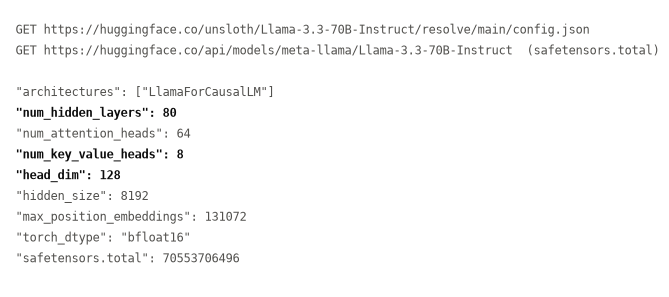

In [8]:
api = requests.get("https://huggingface.co/api/models/meta-llama/Llama-3.3-70B-Instruct", timeout=30).json()
cfg = requests.get("https://huggingface.co/unsloth/Llama-3.3-70B-Instruct/resolve/main/config.json", timeout=30).json()
P = api["safetensors"]["total"]
L, n_heads, n_kv, hidden = cfg["num_hidden_layers"], cfg["num_attention_heads"], cfg["num_key_value_heads"], cfg["hidden_size"]
if cfg.get("head_dim"):
    d_head, head_dim_note = cfg["head_dim"], "head_dim read directly from config.json"
else:
    d_head, head_dim_note = hidden // n_heads, f"head_dim absent: hidden_size / num_attention_heads = {hidden}/{n_heads}"
fields = {k: cfg.get(k) for k in ("architectures", "num_hidden_layers", "num_attention_heads", "num_key_value_heads",
                                  "head_dim", "hidden_size", "max_position_embeddings", "torch_dtype")}
print(f"parameters (Hub API safetensors.total) = {P:,}")
print(head_dim_note, "=", d_head)
print(json.dumps(fields, indent=1))
(RESULTS / "llama33_config.json").write_text(json.dumps(cfg, indent=2))

fig, ax = plt.subplots(figsize=(7.2, 3.6))
ax.axis("off")
lines = ["GET https://huggingface.co/unsloth/Llama-3.3-70B-Instruct/resolve/main/config.json",
         "GET https://huggingface.co/api/models/meta-llama/Llama-3.3-70B-Instruct  (safetensors.total)", ""]
lines += [f'"{k}": {json.dumps(v)}' for k, v in fields.items()] + [f'"safetensors.total": {P}']
for i, line in enumerate(lines):
    hl = any(s in line for s in ("num_hidden_layers", "num_key_value_heads", "head_dim"))
    ax.text(0.01, 0.95 - i * 0.075, line, family="monospace", fontsize=8.5, weight="bold" if hl else "normal",
            color="#0b0b0b" if hl else "#52514e", transform=ax.transAxes, va="top")
fig.savefig(RESULTS / "llama33_config.png", dpi=200, bbox_inches="tight")
plt.show()

In [9]:
GB = 1e9
weights = {bits: P * bits / 8 / GB for bits in (16, 8, 4)}
S_max = int(I[-1] + O[-1])
kv_per_token = 2 * L * n_kv * d_head * 2
kv_seq = kv_per_token * S_max / GB
for bits, gb in weights.items():
    print(f"weights @ {bits:2d}-bit = {P:,} * {bits}/8 bytes = {gb:,.2f} GB")
print(f"\nS = I_N + O_N = {I[-1]} + {O[-1]} = {S_max} tokens")
print(f"KV/token = 2 * {L} * {n_kv} * {d_head} * 2 B = {kv_per_token:,} B ({kv_per_token / 1024:.0f} KiB)")
print(f"KV/sequence = {kv_per_token:,} * {S_max} = {kv_per_token * S_max:,} B = {kv_seq:.3f} GB")

GPU_NAME, GPU_GB, GPU_PRICE = "NVIDIA A100 80GB SXM (RunPod Secure Cloud, on-demand)", 80, 1.79
usable = 0.9 * GPU_GB
kv_budget = usable - weights[4]
per_gpu = math.floor(kv_budget / kv_seq)
print(f"\nGPU: {GPU_NAME}, {GPU_GB} GB, ${GPU_PRICE}/GPU-hour")
print(f"usable = 0.9 * {GPU_GB} = {usable:.1f} GB; KV budget = {usable:.1f} - {weights[4]:.2f} = {kv_budget:.2f} GB")
print(f"max concurrent sequences per GPU = floor({kv_budget:.2f} / {kv_seq:.3f}) = {per_gpu}")
bw = 2039  # GB/s, A100 80GB SXM memory bandwidth (NVIDIA spec sheet)
print(f"sanity check (estimate, not a measurement): single-stream decode is memory-bound, "
      f"<= {bw} GB/s / {weights[4]:.1f} GB = {bw / weights[4]:.0f} tokens/s")
out["selfhost"] = dict(model="meta-llama/Llama-3.3-70B-Instruct", params=P, layers=L, heads=n_heads, kv_heads=n_kv, head_dim=d_head,
                       head_dim_note=head_dim_note, hidden=hidden, weights_gb=weights, S_max=S_max, kv_per_token=kv_per_token,
                       kv_seq_gb=kv_seq, gpu=GPU_NAME, gpu_gb=GPU_GB, gpu_price=GPU_PRICE, usable_gb=usable,
                       kv_budget_gb=kv_budget, per_gpu=per_gpu, decode_bound_tps=bw / weights[4])

weights @ 16-bit = 70,553,706,496 * 16/8 bytes = 141.11 GB
weights @  8-bit = 70,553,706,496 * 8/8 bytes = 70.55 GB
weights @  4-bit = 70,553,706,496 * 4/8 bytes = 35.28 GB

S = I_N + O_N = 5200 + 600 = 5800 tokens
KV/token = 2 * 80 * 8 * 128 * 2 B = 327,680 B (320 KiB)
KV/sequence = 327,680 * 5800 = 1,900,544,000 B = 1.901 GB

GPU: NVIDIA A100 80GB SXM (RunPod Secure Cloud, on-demand), 80 GB, $1.79/GPU-hour
usable = 0.9 * 80 = 72.0 GB; KV budget = 72.0 - 35.28 = 36.72 GB
max concurrent sequences per GPU = floor(36.72 / 1.901) = 19
sanity check (estimate, not a measurement): single-stream decode is memory-bound, <= 2039 GB/s / 35.3 GB = 58 tokens/s


## Section 2.6 — Latency budget
*(This comes before the GPU count and the break-even, because both use the end-to-end latency.)*

**Tool delay** $t$ = the median of **all** pooled tool measurements (OpenAQ, Open-Meteo, heat index, KB lookup), applied to every tool call.

**Per call**: $\ell_k = \text{TTFT}(I_k) + \frac{O_k + r}{\text{tps}}$. Prefill grows with the input, so TTFT is linear in input length:
$\text{TTFT}(I) = a + bI$, fitted through Artificial Analysis' measured TTFT at 1k and 10k input tokens on the same endpoint.

**Per query**: $L = \sum_{k=1}^{N}\ell_k + (N-1)\,t + p\sum_{k=1}^{N-1}(\ell_k + t)$, where the last term is the expected retry delay.

**Candidate rule.** A candidate must fit within B with caching, without its cost being a lower bound. It must have verified TTFT and throughput for that endpoint, and support tool calling and JSON. On each side, the candidate is the eligible model with the highest tool-use score.

In [10]:
log = pd.read_csv("timing_log.csv")
ok = log[log.status == "ok"]
per_tool = ok.groupby("tool").latency_ms.agg(["count", "median", "mean", "min", "max"])
days = ok.timestamp_utc.str[:10].nunique()
t_tool_ms = ok.latency_ms.median()
t_tool = t_tool_ms / 1000
print(f"successful measurements: {len(ok)} over {days} day(s); errors logged: {(log.status != 'ok').sum()}")
print(per_tool.round(4))
print(f"\npooled median tool delay t = {t_tool_ms:.4f} ms")
missing = [tl for tl in ("air_quality", "weather") if tl not in per_tool.index or per_tool.loc[tl, "count"] < 20]
complete = not missing and days >= 2
if not complete:
    print(f"INCOMPLETE LOG: needs >=20 OK calls each for {missing or 'both APIs'} over >=2 days (currently {days}).")
out["tools"] = dict(per_tool=per_tool.reset_index().to_dict(orient="records"), median_ms=t_tool_ms, days=days,
                    n_ok=len(ok), n_err=int((log.status != "ok").sum()), complete=complete)

successful measurements: 75 over 1 day(s); errors logged: 25
            count    median      mean       min        max
tool                                                      
heat_index     25    0.0044    0.0050    0.0030     0.0128
kb_lookup      25    0.0323    0.0395    0.0189     0.2185
weather        25  133.1913  192.1374  128.6525  1483.7140

pooled median tool delay t = 0.0323 ms
INCOMPLETE LOG: needs >=20 OK calls each for ['air_quality'] over >=2 days (currently 1).


In [11]:
merged_inputs = costs.merge(inputs, on=["model", "side", "endpoint"])
eligible = merged_inputs[merged_inputs.fits_B_cache & ~merged_inputs.lower_bound
                         & merged_inputs.ttft_s.notna() & merged_inputs.tps.notna()]
candidates = eligible.loc[eligible.groupby("side").tool_score.idxmax()].set_index("model")
print(candidates[["side", "tool_bench", "tool_score", "cost_cache", "ttft_1k_s", "ttft_10k_s", "tps"]])


def ttft_fit(c):
    b = (c.ttft_10k_s - c.ttft_1k_s) / 9000
    return c.ttft_1k_s - 1000 * b, b


def query_latency(call_lat):
    retries = p * (call_lat[:-1] + t_tool).sum()
    return call_lat.sum() + (N - 1) * t_tool + retries, retries


lat = {}
for name, c in candidates.iterrows():
    a, b = ttft_fit(c)
    ttft_k = a + b * I
    call_lat = ttft_k + O / c.tps
    total, retries = query_latency(call_lat)
    lat[name] = dict(a=a, b=b, ttft_k=ttft_k.tolist(), call_lat=call_lat.tolist(), tools=(N - 1) * t_tool, retries=retries,
                     total=total, meets_T=bool(total <= T), tps=c.tps, source=c.ttft_workload_source)
    print(f"\n{name}: TTFT(I) = {a:.4f} + {b * 1000:.5f} s/1k tokens * I   (from {c.ttft_1k_s} s @1k, {c.ttft_10k_s} s @10k)")
    for kk, i, tt, cl in zip(k, I, ttft_k, call_lat):
        print(f"  call {kk}: TTFT({i}) = {tt:.3f} s + {O[kk - 1]}/{c.tps} = {cl:.2f} s")
    print(f"  tools: {N - 1} * {t_tool * 1000:.4f} ms = {(N - 1) * t_tool:.4f} s")
    print(f"  retries: {p} * sum_(k<N)(l_k + t) = {retries:.2f} s")
    print(f"  L = {total:.2f} s vs T = {T} s -> {'meets' if total <= T else 'EXCEEDS'} T")

                    side             tool_bench  tool_score  cost_cache  ttft_1k_s  ttft_10k_s    tps
model                                                                                                
Claude Haiku 5.5  closed     AutomationBench-AA        22.9  229.655920      5.231       8.937  220.3
MiniMax-M3          open  AA tau2-Bench Telecom        88.9  480.002624      0.705       0.877   40.1

Claude Haiku 5.5: TTFT(I) = 4.8192 + 0.41178 s/1k tokens * I   (from 5.231 s @1k, 8.937 s @10k)
  call 1: TTFT(2000) = 5.643 s + 350/220.3 = 7.23 s
  call 2: TTFT(2800) = 5.972 s + 350/220.3 = 7.56 s
  call 3: TTFT(3600) = 6.302 s + 350/220.3 = 7.89 s
  call 4: TTFT(4400) = 6.631 s + 350/220.3 = 8.22 s
  call 5: TTFT(5200) = 6.960 s + 600/220.3 = 9.68 s
  tools: 4 * 0.0323 ms = 0.0001 s
  retries: 0.09 * sum_(k<N)(l_k + t) = 2.78 s
  L = 43.37 s vs T = 9 s -> EXCEEDS T

MiniMax-M3: TTFT(I) = 0.6859 + 0.01911 s/1k tokens * I   (from 0.705 s @1k, 0.877 s @10k)
  call 1: TTFT(2000) = 0.7

**Architectural change: route the simple tool-selection steps (calls 1..N−1) to a small, fast model.** The candidate itself only writes the final answer (call N).
The router is the fastest verified non-reasoning model in the table that supports tools and JSON and fits B: **Qwen3.8-27B** on Multiverse (TTFT 1.663 s, 225.8 tok/s, Apache-2.0).
Only its headline TTFT is published, so its TTFT is held constant. The cost of the routed design is recalculated too: calls 1..N−1 are billed at the router's prices, call N at the candidate's.

In [12]:
router = inputs.set_index("model").loc["Qwen3.8-27B"]
router_call = router.ttft_s + O[:-1] / router.tps
r_in, r_out, r_calls = (1 + p) * I[:-1].sum(), (1 + p) * O[:-1].sum(), (1 + p) * (N - 1)
f_in, f_out, f_calls = I[-1], O[-1], 1
print(f"router call = {router.ttft_s} + 350/{router.tps} = {router_call[0]:.3f} s")
print(f"router tokens/query: in = (1+p)*{I[:-1].sum()} = {r_in:.0f}, out = (1+p)*{O[:-1].sum()} = {r_out:.0f}, calls = {r_calls:.2f}")
for name, c in candidates.iterrows():
    a, b = lat[name]["a"], lat[name]["b"]
    final = a + b * I[-1] + O[-1] / c.tps
    call_lat = np.append(router_call, final)
    total, retries = query_latency(call_lat)
    cand_row = inputs.set_index("model").loc[name]
    router_cost = monthly_cost(router, M, r_in, r_out, r_calls)[1]
    final_cost = monthly_cost(cand_row, M, f_in, f_out, f_calls)[1]
    lat[name].update(routed_calls=call_lat.tolist(), routed_retries=retries, routed_total=total,
                     routed_meets_T=bool(total <= T), routed_cost=router_cost + final_cost,
                     routed_cost_parts=dict(router=router_cost, final=final_cost))
    print(f"\n{name} + router: calls 1-{N - 1} = {router_call[0]:.3f} s each; call {N} = TTFT({I[-1]}) + {O[-1]}/{c.tps} = {final:.2f} s")
    print(f"  retries {retries:.2f} s; L' = {total:.2f} s -> {'meets' if total <= T else 'still exceeds'} T = {T} s")
    print(f"  monthly cost (with caching) = router ${router_cost:,.2f} + final ${final_cost:,.2f} = ${router_cost + final_cost:,.2f}")

out["latency"] = lat
out["router"] = dict(model="Qwen3.8-27B", ttft=router.ttft_s, tps=router.tps)
out["candidates"] = candidates.reset_index()[["model", "side", "tool_bench", "tool_score", "cost_cache"]].to_dict(orient="records")

router call = 1.663 + 350/225.8 = 3.213 s
router tokens/query: in = (1+p)*12800 = 13952, out = (1+p)*1400 = 1526, calls = 4.36

Claude Haiku 5.5 + router: calls 1-4 = 3.213 s each; call 5 = TTFT(5200) + 600/220.3 = 9.68 s
  retries 1.16 s; L' = 23.69 s -> still exceeds T = 9 s
  monthly cost (with caching) = router $147.72 + final $70.81 = $218.53

MiniMax-M3 + router: calls 1-4 = 3.213 s each; call 5 = TTFT(5200) + 600/40.1 = 15.75 s
  retries 1.16 s; L' = 29.76 s -> still exceeds T = 9 s
  monthly cost (with caching) = router $147.72 + final $146.43 = $294.15


## Section 2.4 (items 3–4) — Concurrent sessions and GPUs required
A session holds its KV cache for the whole agent loop, so by **Little's law** the number of live sessions at peak is
$C = \lambda_{peak} \times L$, with $\lambda_{peak} = \frac{0.35 \cdot 5Q}{7200\text{ s}}$ and $L$ the end-to-end latency per query.
I use $L$ of the faster candidate *after* the architectural change, the realistic query duration from Section 2.6.
GPUs $= \lceil C / \text{per-GPU capacity}\rceil$ (minimum 1), each billed for the full month: 30 × 24 = 720 h.

In [13]:
L_sess = min(v["routed_total"] for v in lat.values())


def gpus_needed(daily_q, session_s=L_sess):
    conc = 0.35 * 5 * daily_q / 7200 * session_s
    return max(1, math.ceil(conc / per_gpu)), conc


n_gpu, conc = gpus_needed(Q)
lam = 0.35 * 5 * Q / 7200
print(f"lambda_peak = 0.35 * 5 * {Q} / 7200 s = {lam:.4f} queries/s")
print(f"C = {lam:.4f} * {L_sess:.2f} s = {conc:.2f} concurrent sessions")
print(f"GPUs = ceil({conc:.2f} / {per_gpu}) = {n_gpu}  ->  {n_gpu} * ${GPU_PRICE} * 720 h = ${n_gpu * GPU_PRICE * 720:,.2f}/month")
out["selfhost"].update(session_s=L_sess, lam=lam, concurrent=conc, gpus=n_gpu, monthly=n_gpu * GPU_PRICE * 720)

lambda_peak = 0.35 * 5 * 2200 / 7200 s = 0.5347 queries/s
C = 0.5347 * 23.69 s = 12.67 concurrent sessions
GPUs = ceil(12.67 / 19) = 1  ->  1 * $1.79 * 720 h = $1,288.80/month


## Section 2.5 — Break-even: self-hosting vs the API
* Self-hosting: $C_{self}(Q') = g(Q')\cdot \$1.79 \cdot 720$, with $g(Q') = \max\big(1, \lceil \lambda_{peak}(Q')\,L / \text{capacity}\rceil\big)$, a step function.
* API: the comparator's monthly cost recomputed at volume $Q'$ (linear in $Q'$ apart from the fixed cache-write term).
* Comparator: the cheaper item-6 candidate that meets $T$ after the change. If neither does, the one with the lower latency after the change.
* Both are evaluated over $Q' = 250 \dots 60{,}000$ normal-day queries per day. $Q^*$ is the first volume where self-hosting is cheaper.

comparator: Claude Haiku 5.5 + Qwen3.8-27B router (neither candidate meets T after the change, so the one with the lower latency); L' = 23.69 s


API at Q=2200: $218.53/month = $0.0993 per daily query
one GPU serves up to 19 sessions -> 3,299 daily queries; $1,288.80 / 3,299 = $0.3906 per daily query once GPUs are full
no Q* up to 60,000/day: each added GPU costs $0.3906 per daily query, the API $0.0993


what-if sessions lasted only T = 9 s: Q* = None


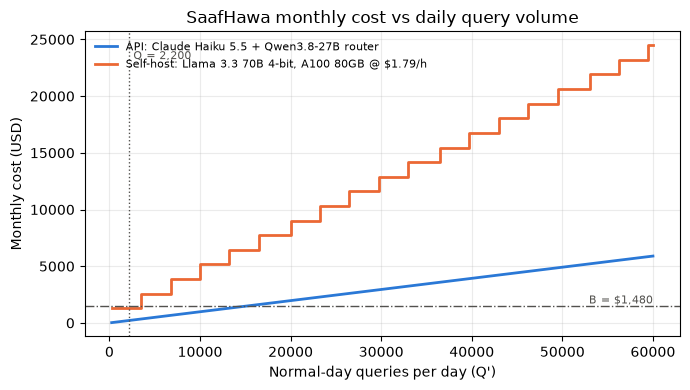

In [14]:
meeting = [m for m, v in lat.items() if v["routed_meets_T"]]
if meeting:
    comparator = min(meeting, key=lambda m: lat[m]["routed_cost"])
    rule = "cheaper candidate that meets T after the change"
else:
    comparator = min(lat, key=lambda m: lat[m]["routed_total"])
    rule = "neither candidate meets T after the change, so the one with the lower latency"
cand_row = inputs.set_index("model").loc[comparator]
print(f"comparator: {comparator} + Qwen3.8-27B router ({rule}); L' = {lat[comparator]['routed_total']:.2f} s")


def api_cost_at(q):
    months_q = (30 - H) * q + H * 5 * q
    return (monthly_cost(router, months_q, r_in, r_out, r_calls)[1]
            + monthly_cost(cand_row, months_q, f_in, f_out, f_calls)[1])


grid = np.arange(250, 60001, 250)
api_curve = np.array([api_cost_at(q) for q in grid])
self_curve = np.array([gpus_needed(q)[0] for q in grid]) * GPU_PRICE * 720
cheaper = np.where(self_curve < api_curve)[0]
Q_star = int(grid[cheaper[0]]) if len(cheaper) else None
step = per_gpu * 7200 / (0.35 * 5 * L_sess)
api_per_q = api_cost_at(Q) / Q
gpu_per_q = GPU_PRICE * 720 / step
print(f"API at Q={Q}: ${api_cost_at(Q):,.2f}/month = ${api_per_q:.4f} per daily query")
print(f"one GPU serves up to {per_gpu} sessions -> {step:,.0f} daily queries; ${GPU_PRICE * 720:,.2f} / {step:,.0f} = "
      f"${gpu_per_q:.4f} per daily query once GPUs are full")
print(f"Q* = {Q_star:,} queries/day" if Q_star else
      f"no Q* up to {grid[-1]:,}/day: each added GPU costs ${gpu_per_q:.4f} per daily query, the API ${api_per_q:.4f}")
Q_star_T = next((int(q) for q in grid if gpus_needed(q, T)[0] * GPU_PRICE * 720 < api_cost_at(q)), None)
print(f"what-if sessions lasted only T = {T} s: Q* = {Q_star_T}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(grid, api_curve, color="#2a78d6", lw=2, label=f"API: {comparator} + Qwen3.8-27B router")
ax.step(grid, self_curve, where="post", color="#eb6834", lw=2, label=f"Self-host: Llama 3.3 70B 4-bit, A100 80GB @ ${GPU_PRICE}/h")
ax.axvline(Q, color="#52514e", lw=1, ls=":")
ax.text(Q, self_curve.max() * 0.95, f" Q = {Q:,}", color="#52514e", fontsize=8)
if Q_star:
    ax.axvline(Q_star, color="#0b0b0b", lw=1, ls="--")
    ax.text(Q_star, self_curve.max() * 0.85, f" Q* = {Q_star:,}", fontsize=8)
ax.axhline(B, color="#52514e", lw=1, ls="-.")
ax.text(grid[-1], B, f"B = ${B:,}", ha="right", va="bottom", fontsize=8, color="#52514e")
ax.set_xlabel("Normal-day queries per day (Q')")
ax.set_ylabel("Monthly cost (USD)")
ax.set_title("SaafHawa monthly cost vs daily query volume")
ax.grid(alpha=0.25)
ax.legend(fontsize=8, loc="upper left", frameon=False)
fig.tight_layout()
fig.savefig(RESULTS / "breakeven.png", dpi=200)
plt.show()
out["breakeven"] = dict(comparator=comparator, rule=rule, api_at_Q=api_cost_at(Q), selfhost_at_Q=gpus_needed(Q)[0] * GPU_PRICE * 720,
                        Q_star=Q_star, Q_star_if_T=Q_star_T, queries_per_gpu=step, api_per_daily_query=api_per_q,
                        gpu_per_daily_query=gpu_per_q, grid_max=int(grid[-1]))

In [15]:
(RESULTS / "q1_results.json").write_text(json.dumps(out, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o)))
print("saved results/q1_results.json")

saved results/q1_results.json
